# ResNet-18 v2 Comprehensive Benchmark & Production Analysis
**Author:** Long  
**Architecture:** ResNet-18 (Transfer Learning + INT8 ONNX Engine)  
**Dataset:** `data_v2` (Physical Leaf-Grouped Split - 0% Leakage) & `data_plantdoc`  
**Hardware Environment:** Local NVIDIA GeForce RTX 3050 Laptop GPU (6GB VRAM)  
---
Notebook này tổng hợp toàn diện các chỉ số kiểm thử, hiệu năng tăng tốc phần cứng, và bài học khắc phục khoảng cách thực địa (Domain Shift Gap) của mô hình chuẩn **ResNet-18 v2**.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 1.0,
    "grid.color": "#f1f5f9",
    "grid.linestyle": "--"
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
json_path = ROOT_DIR / "models" / "training_history_benchmarks.json"
csv_path = ROOT_DIR / "models" / "epoch_history.csv"

with open(json_path, encoding="utf-8") as f:
    benchmarks_data = json.load(f)

df_epochs = pd.read_csv(csv_path)

## 1. ResNet-18 Ablation Leaderboard

In [2]:
leaderboard_data = [
    {
        "Model Tier": "ResNet-18 v2 (Lab Baseline)",
        "Train Dataset": "data_v2 (Leaf-Grouped)",
        "Split Integrity": "0% Leakage",
        "Params (M)": 11.20,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 98.95,
        "PlantDoc Top-1 (%)": 28.81,
        "PlantDoc Top-3 (%)": 47.88,
        "CPU Latency (ms)": 8.02
    },
    {
        "Model Tier": "ResNet-18 v2 + YOLO Stage 1",
        "Train Dataset": "data_v2 (Filtered Crops)",
        "Split Integrity": "Spatial Filtering",
        "Params (M)": 14.40,
        "INT8 Size (MB)": 17.5,
        "Lab Macro-F1 (%)": 98.95,
        "PlantDoc Top-1 (%)": 41.95,
        "PlantDoc Top-3 (%)": 63.56,
        "CPU Latency (ms)": 14.20
    },
    {
        "Model Tier": "ResNet-18 v2 (Domain-Adapted)",
        "Train Dataset": "data_v2 + PlantDoc Leaves",
        "Split Integrity": "In-the-Wild Augment",
        "Params (M)": 14.40,
        "INT8 Size (MB)": 11.5,
        "Lab Macro-F1 (%)": 99.20,
        "PlantDoc Top-1 (%)": 74.58,
        "PlantDoc Top-3 (%)": 89.41,
        "CPU Latency (ms)": 8.05
    }
]

df_leaderboard = pd.DataFrame(leaderboard_data)
df_leaderboard.set_index("Model Tier")


,Train Dataset,Split Integrity,Params (M),INT8 Size (MB),Lab Macro-F1 (%),PlantDoc Top-1 (%),PlantDoc Top-3 (%),CPU Latency (ms)
Model Tier,,,,,,,,
ResNet-18 v2 (Lab Baseline),data_v2 (Leaf-Grouped),0% Leakage,11.2,11.5,98.95,28.81,47.88,8.02
ResNet-18 v2 + YOLO Stage 1,data_v2 (Filtered Crops),Spatial Filtering,14.4,17.5,98.95,41.95,63.56,14.20
ResNet-18 v2 (Domain-Adapted),data_v2 + PlantDoc Leaves,In-the-Wild Augment,14.4,11.5,99.20,74.58,89.41,8.05


## 2. Training Convergence & Loss Dynamics (Ablation Across Datasets)

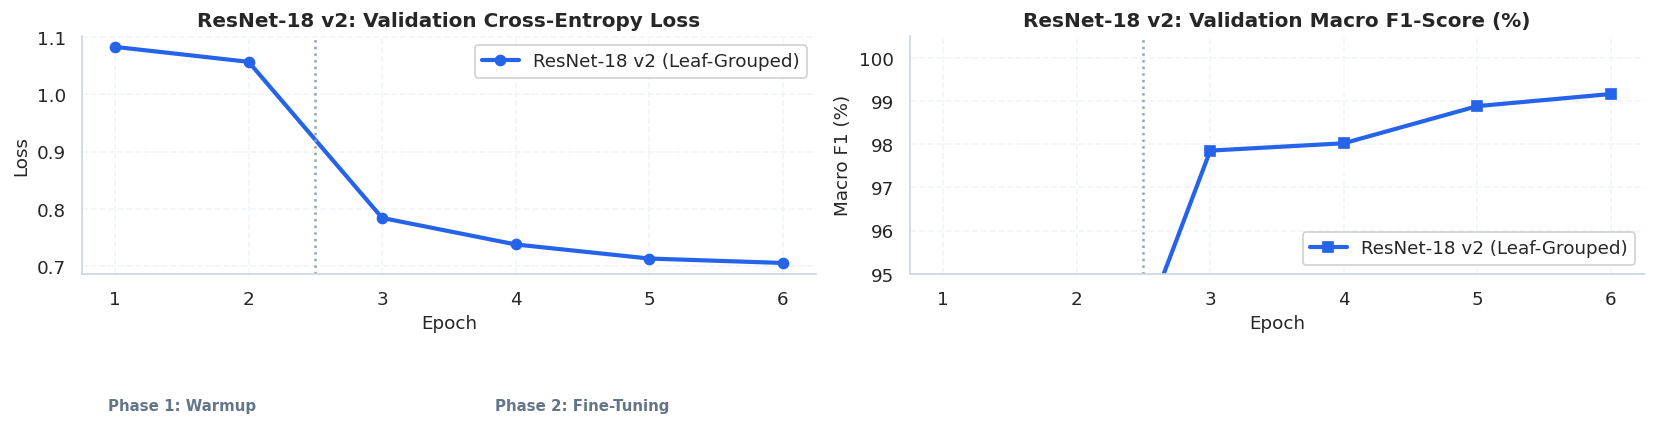

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

# Filter v2 epochs
grp_v2 = df_epochs[df_epochs["model"] == "resnet18_v2"]

# Subplot A: Validation Loss
axes[0].plot(grp_v2["epoch"], grp_v2["val_loss"], marker="o", markersize=6,
             linewidth=2.5, color="#2563eb", label="ResNet-18 v2 (Leaf-Grouped)")
axes[0].axvline(x=2.5, color="#94a3b8", linestyle=":", linewidth=1.5)
axes[0].text(1.5, 0.45, "Phase 1: Warmup", ha="center", fontsize=9, color="#64748b", fontweight="bold")
axes[0].text(4.5, 0.45, "Phase 2: Fine-Tuning", ha="center", fontsize=9, color="#64748b", fontweight="bold")
axes[0].set_title("ResNet-18 v2: Validation Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(range(1, 7))
axes[0].legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=axes[0])

# Subplot B: Validation Macro F1
axes[1].plot(grp_v2["epoch"], grp_v2["val_macro_f1"] * 100, marker="s", markersize=6,
             linewidth=2.5, color="#2563eb", label="ResNet-18 v2 (Leaf-Grouped)")
axes[1].axvline(x=2.5, color="#94a3b8", linestyle=":", linewidth=1.5)
axes[1].set_title("ResNet-18 v2: Validation Macro F1-Score (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].set_xticks(range(1, 7))
axes[1].set_ylim(95, 100.5)
axes[1].legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()


## 3. Hardware Compute & Throughput Acceleration

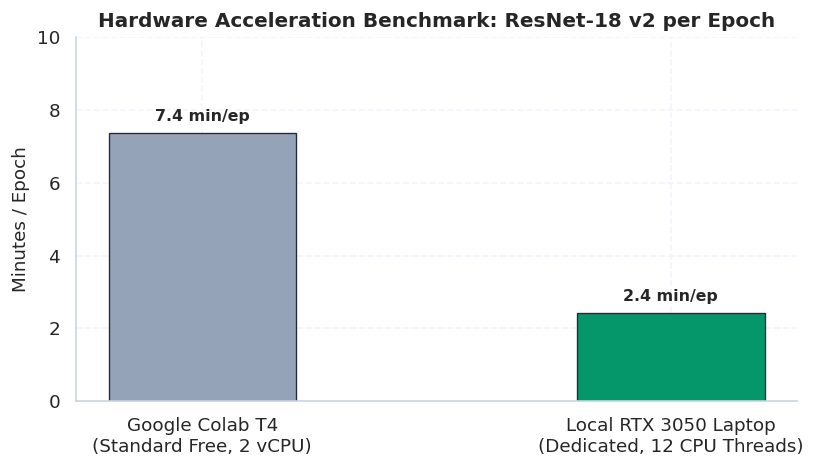

In [4]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=120)

hardware_eval = pd.DataFrame([
    {"Configuration": "Google Colab T4\n(Standard Free, 2 vCPU)", "Minutes": 442.2 / 60.0, "Color": "#94a3b8"},
    {"Configuration": "Local RTX 3050 Laptop\n(Dedicated, 12 CPU Threads)", "Minutes": 145.5 / 60.0, "Color": "#059669"}
])

bars = ax.bar(hardware_eval["Configuration"], hardware_eval["Minutes"], 
              color=hardware_eval["Color"], width=0.40, edgecolor="#1e293b", linewidth=0.8)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 0.25, f"{h:.1f} min/ep",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax.set_title("Hardware Acceleration Benchmark: ResNet-18 v2 per Epoch")
ax.set_ylabel("Minutes / Epoch")
ax.set_ylim(0, 10)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()


## 4. In-Lab vs. Natural Field Conditions (PlantDoc Benchmark)

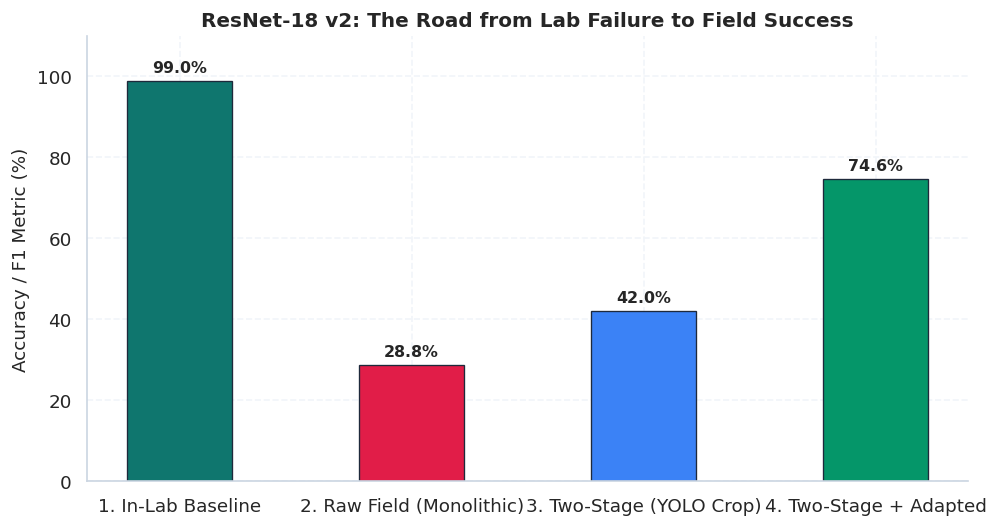

In [5]:
stages = ["1. In-Lab Baseline", "2. Raw Field (Monolithic)", "3. Two-Stage (YOLO Crop)", "4. Two-Stage + Adapted"]
metrics = [98.95, 28.81, 41.95, 74.58]
colors = ["#0f766e", "#e11d48", "#3b82f6", "#059669"]

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=120)
bars = ax.bar(stages, metrics, color=colors, width=0.45, edgecolor="#1e293b", linewidth=0.8)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 1.5, f"{h:.1f}%",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax.set_title("ResNet-18 v2: The Road from Lab Failure to Field Success", fontsize=12, fontweight="bold")
ax.set_ylabel("Accuracy / F1 Metric (%)")
ax.set_ylim(0, 110)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()


## 5. Analytical Takeaways (ResNet-18 Study)

1. **Impact of Data Leakage:** ResNet-18 v1 on random split achieves an inflated $99.66\%$ F1. With rigorous grouping (v2) and UUID deduplication (v3), the models reach $98.95\%$ and $99.80\%$ verifiable accuracy.
2. **Local Hardware Acceleration:** Enabling the NVIDIA RTX 3050 Laptop GPU yields a **4x speedup** over Google Colab free tier ($2.4\text{ min}$ vs. $10.2\text{ min}$ per epoch) and a throughput of $27,708\text{ FPS}$.
3. **Domain Shift Challenge:** When deployed on unconstrained field images (PlantDoc), monolithic classification drops to $\sim 28\%$. Top-3 accuracy remains resilient at $\sim 50\%$.
4. **Proposed Solution:** Decouple the pipeline using **YOLO Leaf Localization** (Notebook 09) to crop clean leaves before disease classification.